# Data-driven modeling basics — regression, overfitting, optimization, training

The whole Part-I pipeline on one 1-D problem: fit $y=\sin(2\pi x)+$noise from a few samples. We see the **train/validation/test** split, **underfitting vs overfitting** and the sweet spot between them, why a **spatial split** turns validation into extrapolation, how **regularization** helps, what **gradient descent** does on a loss surface, and what an honest **training run** looks like with mini-batches, validation tracking and early stopping.

### Setup, target function, and an i.i.d. train/validation/test split

Import NumPy, PyTorch and Matplotlib, apply the course plotting style, set `float64` as the default dtype, and **fix the seeds** (`torch` and `numpy`) so the noisy data and every fit are reproducible. The target is the curved function
$$ f(x) = \sin(2\pi x), \qquad x\in[0,1], $$
sampled at $n=60$ uniformly random points and corrupted with Gaussian noise, $y_i = f(x_i) + \varepsilon_i,\ \varepsilon_i\sim\mathcal N(0,0.15^2)$. The points are split **at random** into 36 training, 12 validation and 12 test points, so all three sets cover the same range of $x$. The training set fits parameters, the validation set chooses between models, and the test set is touched **once**, at the end. `FIG` is where the dual light/dark figures are written.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.nets import MLP
from pyutils import set_plot_style, save_dual, fg, muted
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG, exist_ok=True)
f = lambda x: np.sin(2*np.pi*x)
n = 60; x = np.random.rand(n); y = f(x) + 0.15*np.random.randn(n)
# i.i.d. random split: train / validation / test cover the same range of x
perm = np.random.permutation(n); itr, iva, ite = perm[:36], perm[36:48], perm[48:]
xtr, ytr = x[itr], y[itr]; xva, yva = x[iva], y[iva]; xte, yte = x[ite], y[ite]
xfine = np.linspace(0, 1, 200)
print(f'{len(xtr)} train / {len(xva)} validation / {len(xte)} test points')

36 train / 12 validation / 12 test points


The print confirms the budget: **36 training, 12 validation and 12 test points**, drawn at random from the same 60 samples, so every set covers the whole interval $[0,1]$. Because the split is i.i.d., a model that does well on validation can be expected to do equally well on test — exactly the assumption the spatial split below will break.

## Polynomial regression: under- vs over-fitting, and the sweet spot

Fit polynomials $\hat y=\sum_{k=0}^{d} w_k\,x^k$ of increasing degree $d$ by **least squares** on the training points. Stacking the powers of $x$ into a Vandermonde design matrix $\mathbf{A}$, each fit solves
$$ \min_{\boldsymbol w}\ \big\lVert \mathbf{A}\boldsymbol w - \boldsymbol y_{\mathrm{tr}}\big\rVert_2^2 $$
via `np.linalg.lstsq` (the normal-equation solution $\boldsymbol w^\star=(\mathbf A^\top\mathbf A)^{-1}\mathbf A^\top\boldsymbol y$). The cell fits every degree $d=1,\dots,15$, draws the fits for $d\in\{1,5,15\}$, plots training and validation MSE against degree, **selects the degree with the lowest validation MSE**, and only then reports that one model's test MSE. Low degree **underfits** (too rigid to follow the sine); high degree **overfits** (threads the training noise); the validation curve has a minimum in between. Saved as `ddm_poly_sweep`.

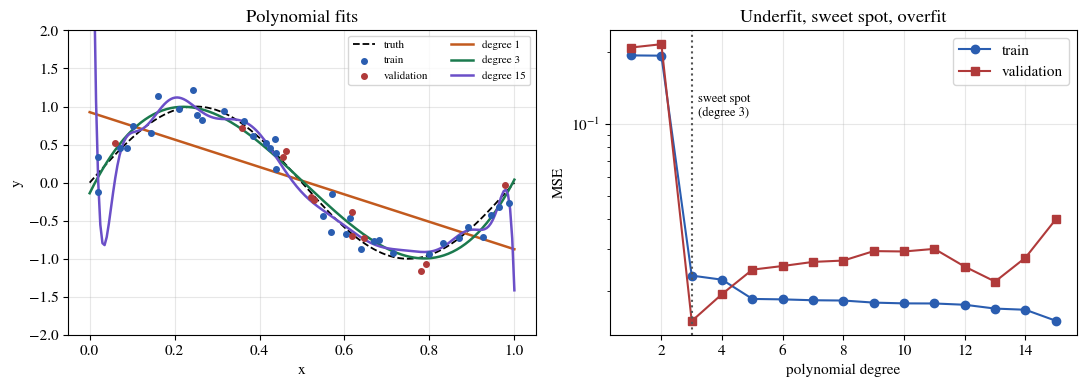

validation MSE: deg1=0.209 deg3=0.015 deg15=0.040
selected degree 3 by validation; its test MSE (reported once) = 0.028


In [2]:
def polyfit_eval(deg, xq, xfit=xtr, yfit=ytr):
    A = np.vander(xfit, deg+1); w, *_ = np.linalg.lstsq(A, yfit, rcond=None)
    return np.vander(xq, deg+1) @ w
degs = list(range(1, 16))
etr = [np.mean((polyfit_eval(d, xtr)-ytr)**2) for d in degs]
eva = [np.mean((polyfit_eval(d, xva)-yva)**2) for d in degs]
best = degs[int(np.argmin(eva))]
ete_best = np.mean((polyfit_eval(best, xte)-yte)**2)

def plot_ddm_poly_sweep():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(xfine, f(xfine), '--', color=fg(), lw=1.3, label='truth')
    ax[0].scatter(xtr, ytr, s=16, color='C0', zorder=3, label='train')
    ax[0].scatter(xva, yva, s=16, color='C3', zorder=3, label='validation')
    for d, c in [(1, 'C1'), (best, 'C2'), (15, 'C4')]:
        ax[0].plot(xfine, polyfit_eval(d, xfine), color=c, lw=1.8, label=f'degree {d}')
    ax[0].set(ylim=(-2, 2), xlabel='x', ylabel='y', title='Polynomial fits'); ax[0].legend(fontsize=8, ncol=2)
    ax[1].semilogy(degs, etr, 'o-', color='C0', label='train')
    ax[1].semilogy(degs, eva, 's-', color='C3', label='validation')
    ax[1].axvline(best, ls=':', color=muted()); ax[1].text(best+0.2, max(eva)*0.5, f'sweet spot\n(degree {best})', fontsize=9)
    ax[1].set(xlabel='polynomial degree', ylabel='MSE', title='Underfit, sweet spot, overfit'); ax[1].legend()
    plt.tight_layout()

save_dual(plot_ddm_poly_sweep, 'ddm_poly_sweep', FIG); plt.show()
print('validation MSE: deg1=%.3f deg%d=%.3f deg15=%.3f' % (eva[0], best, min(eva), eva[-1]))
print(f'selected degree {best} by validation; its test MSE (reported once) = {ete_best:.3f}')

The validation MSE traces a **U**: **0.209 at degree 1, 0.015 at degree 3, 0.040 at degree 15**. The left panel shows why — the line cannot bend; the cubic sits on the truth; the degree-15 curve threads individual training points and swings wildly near the ends, where data is thin. The right panel is the classic diagnostic: **training MSE falls monotonically** (more degrees always fit the training set better) while **validation MSE bottoms out at degree 3** and climbs again. That minimum is the sweet spot, and only the validation set can find it. Having selected degree 3, we touch the test set once: **test MSE 0.028**, consistent with the validation estimate and close to the noise floor $\sigma^2=0.0225$.

## A spatial split turns validation into extrapolation

Same 60 points, different split: training is everything with $x\le 0.6$, validation everything with $x>0.6$. Now the held-out points sit **beyond the training support**, so validation no longer measures generalization to new samples from the same distribution; it measures **extrapolation**. Refit the polynomial sweep and watch what happens to the validation curve.

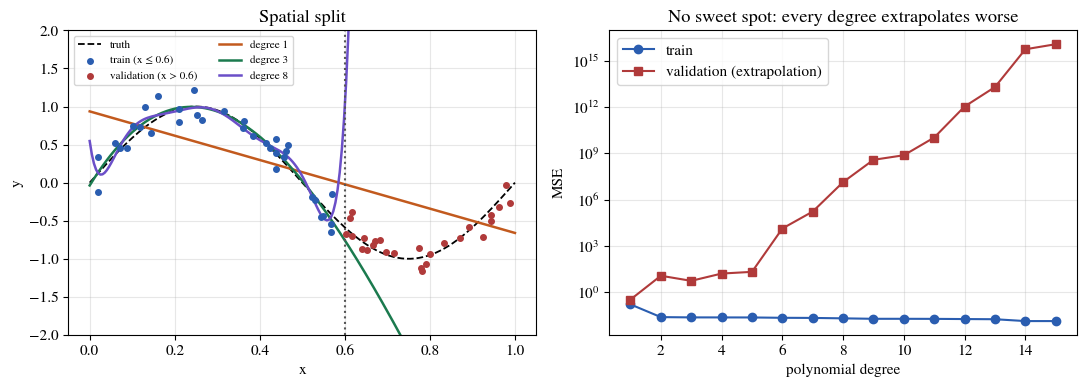

validation MSE under the spatial split: deg1=0.328 deg3=5.386 deg8=1.38e+07
best degree by validation: 1


In [3]:
isp = x <= 0.6
xsp, ysp = x[isp], y[isp]; xsv, ysv = x[~isp], y[~isp]
eva_sp = [np.mean((polyfit_eval(d, xsv, xsp, ysp)-ysv)**2) for d in degs]
etr_sp = [np.mean((polyfit_eval(d, xsp, xsp, ysp)-ysp)**2) for d in degs]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(xfine, f(xfine), '--', color=fg(), lw=1.3, label='truth')
ax[0].scatter(xsp, ysp, s=16, color='C0', zorder=3, label='train (x ≤ 0.6)')
ax[0].scatter(xsv, ysv, s=16, color='C3', zorder=3, label='validation (x > 0.6)')
for d, c in [(1, 'C1'), (3, 'C2'), (8, 'C4')]:
    ax[0].plot(xfine, polyfit_eval(d, xfine, xsp, ysp), color=c, lw=1.8, label=f'degree {d}')
ax[0].axvline(0.6, ls=':', color=muted()); ax[0].set(ylim=(-2, 2), xlabel='x', ylabel='y', title='Spatial split'); ax[0].legend(fontsize=8, ncol=2)
ax[1].semilogy(degs, etr_sp, 'o-', color='C0', label='train'); ax[1].semilogy(degs, eva_sp, 's-', color='C3', label='validation (extrapolation)')
ax[1].set(xlabel='polynomial degree', ylabel='MSE', title='No sweet spot: every degree extrapolates worse'); ax[1].legend()
plt.tight_layout(); plt.show()
print('validation MSE under the spatial split: deg1=%.3f deg3=%.3f deg8=%.3g' % (eva_sp[0], eva_sp[2], eva_sp[7]))
print('best degree by validation:', degs[int(np.argmin(eva_sp))])

Under the spatial split the validation MSE is monotone: **0.328 at degree 1, 5.4 at degree 3, $\sim\!10^7$ at degree 8**, and the "best" model by validation is the **straight line**. This is not overfitting in the usual sense — the cubic fits its own training range well — it is **extrapolation**: every polynomial continues its own trend past $x=0.6$, and the higher the degree the faster it diverges. The lesson is about the split, not the model: a validation set that lies outside the training support measures a different question, and no choice of degree answers it. Part II of the lecture is this situation at scale.

## Neural network with and without L2 regularization

Swap the fixed polynomial basis for a **learned** one: an MLP `MLP([1, 128, 128, 1])` — two hidden layers of 128 `tanh` units — trained by 8000 Adam steps (`lr=5e-3`) minimising the MSE data loss $\frac1n\sum_i(\hat y_i-y_i)^2$. To put it in the scarce-data regime where a flexible model overfits, it sees only the **first 10 of the 36 training points**. The remedy is **L2 regularization** (weight decay): add a penalty on the weights to the cost,
$$ \mathcal L(\boldsymbol\theta) = \mathcal L_{\mathrm{data}}(\boldsymbol\theta) + \lambda\,\lVert\boldsymbol\theta\rVert_2^2, $$
supplied here through Adam's `weight_decay`. The cell fits twice — $\lambda=0$ (no reg) and $\lambda=10^{-2}$ (L2) — and scores each on the **held-out test points**, which cover the same range as the training data.

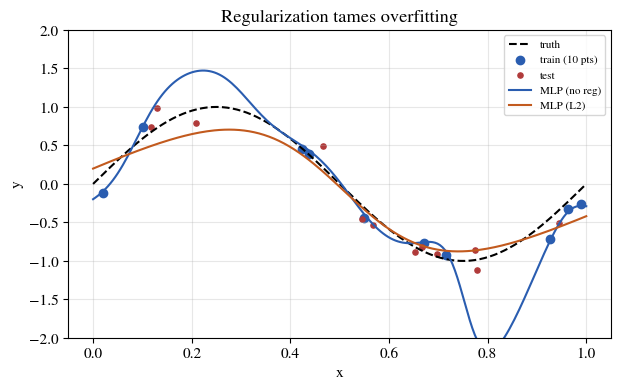

test MSE  no-reg=0.220  L2=0.045


In [4]:
xs12, ys12 = xtr[:10], ytr[:10]
Xs = torch.tensor(xs12).reshape(-1,1); Ys = torch.tensor(ys12).reshape(-1,1)
Xfine = torch.tensor(xfine).reshape(-1,1); Xte = torch.tensor(xte).reshape(-1,1)
def fit_mlp(wd):
    torch.manual_seed(0); net = MLP([1,128,128,1]); opt = torch.optim.Adam(net.parameters(), lr=5e-3, weight_decay=wd)
    for _ in range(8000):
        opt.zero_grad(); loss = ((net(Xs)-Ys)**2).mean(); loss.backward(); opt.step()
    with torch.no_grad(): return net(Xfine).numpy().ravel(), net(Xte).numpy().ravel()
y_no, t_no = fit_mlp(0.0); y_wd, t_wd = fit_mlp(1e-2)
plt.figure(figsize=(7,4)); plt.plot(xfine, f(xfine), '--', color=fg(), label='truth')
plt.scatter(xs12, ys12, c='C0', label='train (10 pts)'); plt.scatter(xte, yte, c='C3', s=14, label='test')
plt.plot(xfine, y_no, label='MLP (no reg)'); plt.plot(xfine, y_wd, label='MLP (L2)')
plt.ylim(-2,2); plt.legend(fontsize=8); plt.title('Regularization tames overfitting'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
mse_te = lambda t: np.mean((t-yte)**2)
print(f'test MSE  no-reg={mse_te(t_no):.3f}  L2={mse_te(t_wd):.3f}')

The test MSE drops from **0.220 (no reg) to 0.045 (L2)** — about **5× lower**. With ten points and a 128-unit-wide network the unregularized fit passes through every training point and swings between them; the L2 penalty $\lambda\lVert\boldsymbol\theta\rVert^2$ shrinks the weights, which smooths the curve and brings it back onto the sine at the held-out points. This is the $\mathcal L_{\mathrm{data}}+\lambda R$ template from the slides with $R=\lVert\boldsymbol\theta\rVert^2$: a little training fit traded for much better generalization.

## Gradient descent on a loss surface

Neural networks are trained by stepping downhill on the cost. To *see* that, take the simplest cost there is: the squared error of a straight line $\hat y = wx+b$ on the training points, a quadratic bowl in the two parameters $(w,b)$:
$$ \mathcal L(w,b) = \frac1N\sum_i (wx_i+b-y_i)^2, \qquad (w,b)\leftarrow(w,b)-\eta\,\nabla\mathcal L . $$
The bowl is elongated because $x$ and the constant $1$ are correlated features, so the gradient does not point at the minimum. Run full-batch gradient descent from the same start with **three learning rates** — a crawl, a good one and one just above the stability limit $2/\lambda_{\max}$ of the Hessian (shown for its first 12 steps) — plus **mini-batch SGD** (batches of 4) at the good rate. Saved as `ddm_gd_surface`.

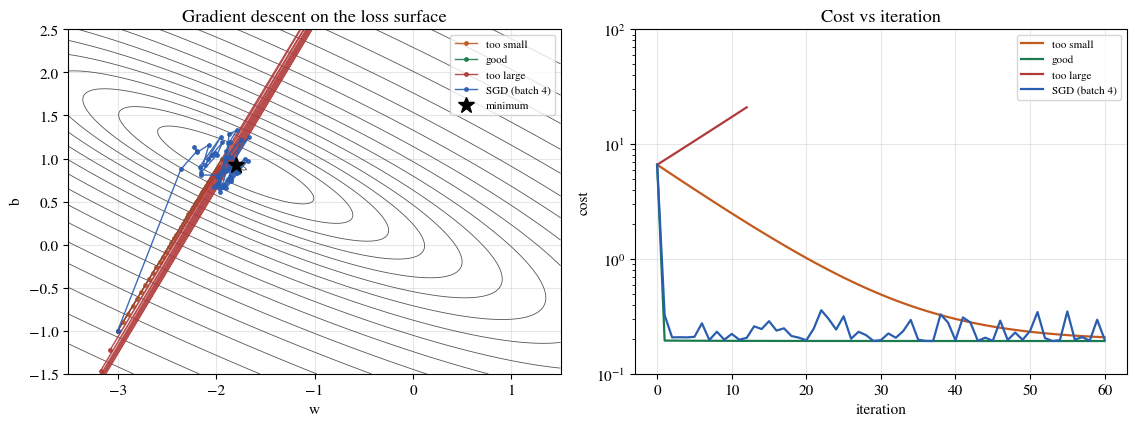

stability limit 2/lambda_max = 0.796;  eta used: too small=0.020, good=0.398, too large=0.816
too small        steps= 60  final cost=0.209
good             steps= 60  final cost=0.194
too large        steps= 12  final cost=20.9
SGD (batch 4)    steps= 60  final cost=0.199


In [5]:
A = np.c_[xtr, np.ones_like(xtr)]                      # features [x, 1]
H = 2*A.T @ A / len(xtr); lam_max = np.linalg.eigvalsh(H).max()
w_star = np.linalg.lstsq(A, ytr, rcond=None)[0]
L = lambda w, b: np.mean((w*xtr + b - ytr)**2)
gradL = lambda th, idx: 2*A[idx].T @ (A[idx] @ th - ytr[idx]) / len(idx)

def descend(eta, steps=60, batch=None, seed=0, stop_at=None):
    rng = np.random.default_rng(seed); th = np.array([-3.0, -1.0]); path = [th.copy()]
    for k in range(steps):
        idx = rng.choice(len(xtr), batch, replace=False) if batch else np.arange(len(xtr))
        th = th - eta*gradL(th, idx); path.append(th.copy())
        if np.abs(th).max() > 50 or (stop_at and k + 1 >= stop_at): break   # diverged / enough shown
    return np.array(path)

etas = {'too small': 0.05/lam_max, 'good': 1.0/lam_max, 'too large': 2.05/lam_max}
paths = {k: descend(e, stop_at=(12 if k == 'too large' else None)) for k, e in etas.items()}
paths['SGD (batch 4)'] = descend(etas['good'], batch=4)
W, B = np.meshgrid(np.linspace(-3.5, 1.5, 200), np.linspace(-1.5, 2.5, 200))
Z = np.array([[L(w, b) for w in W[0]] for b in B[:, 0]])

def plot_ddm_gd_surface():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
    ax[0].contour(W, B, Z, levels=np.geomspace(Z.min()+1e-3, Z.max(), 18), colors=[muted()], linewidths=0.6)
    for (k, P), c in zip(paths.items(), ['C1', 'C2', 'C3', 'C0']):
        ax[0].plot(P[:, 0], P[:, 1], 'o-', color=c, ms=2.5, lw=1.0, alpha=0.9, label=k)
    ax[0].plot(*w_star, '*', color=fg(), ms=12, label='minimum')
    ax[0].set(xlim=(-3.5, 1.5), ylim=(-1.5, 2.5), xlabel='w', ylabel='b', title='Gradient descent on the loss surface'); ax[0].legend(fontsize=8)
    for (k, P), c in zip(paths.items(), ['C1', 'C2', 'C3', 'C0']):
        ax[1].semilogy([L(*p) for p in P], color=c, lw=1.6, label=k)
    ax[1].set(xlabel='iteration', ylabel='cost', title='Cost vs iteration', ylim=(1e-1, 1e2)); ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_ddm_gd_surface, 'ddm_gd_surface', FIG); plt.show()
print(f'stability limit 2/lambda_max = {2/lam_max:.3f};  eta used: ' + ', '.join(f'{k}={e:.3f}' for k, e in etas.items()))
for k, P in paths.items(): print(f'{k:16s} steps={len(P)-1:3d}  final cost={L(*P[-1]):.3g}')

The stability limit is $2/\lambda_{\max}=0.796$ and the three rates are **0.020, 0.398 and 0.816**. Left: the loss surface is a tilted, elongated bowl, and the gradient points across the valley rather than along it. The **good** rate (green) reaches the minimum in a handful of steps; the **too-small** rate (orange) follows the same path but crawls, and after 60 steps still sits at cost 0.209 against the optimum 0.194; the **too-large** rate (red) overshoots across the valley on every step and grows without bound — it is cut off after 12 steps at cost 21. **Mini-batch SGD** (blue) at the good rate reaches the same neighbourhood but keeps jittering around it, because each batch of 4 points sees a slightly different bowl. That noise is what lets SGD escape shallow minima in a non-convex problem, and a decaying learning rate is what removes it at the end.

## Anatomy of a training run

Everything the slides prescribe, in one loop: **standardized** inputs and targets, **mini-batches** of 4 drawn afresh each epoch, one Adam step per batch (`lr=5e-3`), the **training and validation loss tracked every epoch**, and **early stopping** — keep the parameters from the epoch with the lowest validation loss and stop after `patience=500` epochs without improvement. The model is deliberately oversized (`MLP([1, 64, 64, 1])`, 36 training points) so that the validation curve visibly turns upward after the best epoch. The test set is evaluated **once**, with the restored best parameters. The per-epoch curves are noisy because every epoch is nine stochastic steps, so a 25-epoch moving average is drawn on top. Saved as `ddm_loss_curve`.

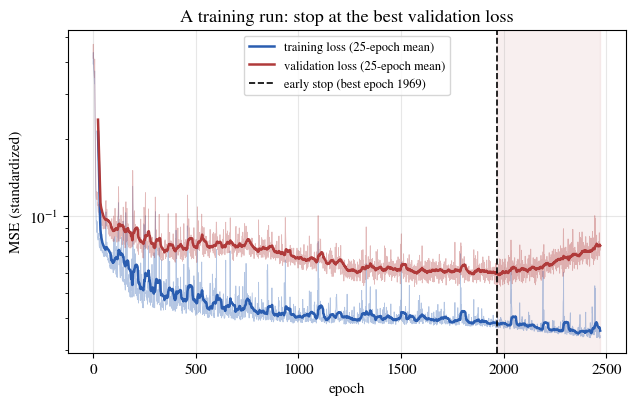

stopped after 2470 epochs; best validation loss 0.0524 at epoch 1969; final validation loss 0.0752
training loss at best epoch 0.0406, at stop 0.0336
test MSE with restored best parameters (reported once): 0.027


In [6]:
xm, xs_, ym, ys_ = xtr.mean(), xtr.std(), ytr.mean(), ytr.std()
T = lambda a: torch.tensor(np.asarray(a).reshape(-1, 1))
Xtr_n, Ytr_n = T((xtr-xm)/xs_), T((ytr-ym)/ys_); Xva_n, Yva_n = T((xva-xm)/xs_), T((yva-ym)/ys_)
Xte_n, Yte_n = T((xte-xm)/xs_), T((yte-ym)/ys_)

torch.manual_seed(0); net = MLP([1, 64, 64, 1]); opt = torch.optim.Adam(net.parameters(), lr=5e-3)
BATCH, EPOCHS, PATIENCE = 4, 4000, 500
hist_tr, hist_va = [], []; best_va, best_ep, best_state, wait = np.inf, 0, None, 0
g = torch.Generator().manual_seed(0)
for ep in range(EPOCHS):
    perm = torch.randperm(len(Xtr_n), generator=g)
    for i in range(0, len(perm), BATCH):                        # one optimizer step per mini-batch
        idx = perm[i:i+BATCH]
        opt.zero_grad(); loss = ((net(Xtr_n[idx]) - Ytr_n[idx])**2).mean(); loss.backward(); opt.step()
    with torch.no_grad():
        ltr = float(((net(Xtr_n) - Ytr_n)**2).mean()); lva = float(((net(Xva_n) - Yva_n)**2).mean())
    hist_tr.append(ltr); hist_va.append(lva)
    if lva < best_va: best_va, best_ep, wait = lva, ep, 0; best_state = {k: v.clone() for k, v in net.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE: break
stopped = ep + 1
net.load_state_dict(best_state)
with torch.no_grad(): test_mse = float(((net(Xte_n) - Yte_n)**2).mean()) * ys_**2   # back to physical units

smooth = lambda h, w=25: np.convolve(h, np.ones(w)/w, mode='valid')
def plot_ddm_loss_curve():
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.semilogy(hist_tr, color='C0', lw=0.6, alpha=0.35); ax.semilogy(hist_va, color='C3', lw=0.6, alpha=0.35)
    ax.semilogy(np.arange(24, len(hist_tr)), smooth(hist_tr), color='C0', lw=1.8, label='training loss (25-epoch mean)')
    ax.semilogy(np.arange(24, len(hist_va)), smooth(hist_va), color='C3', lw=1.8, label='validation loss (25-epoch mean)')
    ax.axvline(best_ep, ls='--', color=fg(), lw=1.2, label=f'early stop (best epoch {best_ep})')
    ax.axvspan(best_ep, stopped, color='C3', alpha=0.08)
    ax.set(xlabel='epoch', ylabel='MSE (standardized)', title=f'A training run: stop at the best validation loss'); ax.legend(fontsize=9)

save_dual(plot_ddm_loss_curve, 'ddm_loss_curve', FIG); plt.show()
print(f'stopped after {stopped} epochs; best validation loss {best_va:.4f} at epoch {best_ep}; final validation loss {hist_va[-1]:.4f}')
print(f'training loss at best epoch {hist_tr[best_ep]:.4f}, at stop {hist_tr[-1]:.4f}')
print(f'test MSE with restored best parameters (reported once): {test_mse:.3f}')
assert hist_va[-1] > best_va                                  # kept training would have overfit

The run stops after **2470 epochs**, having found its **best validation loss (0.0524) at epoch 1969**; by the time patience runs out the validation loss has risen to **0.0752** while the training loss is still falling (0.0406 at the best epoch, 0.0336 at the stop). That widening gap to the right of the dashed line is overfitting happening in real time, and the shaded region is the part of training that early stopping discards. With the best parameters restored, the test set is evaluated once: **test MSE 0.027** in physical units, just above the noise floor of 0.0225. Everything on the "Anatomy of a training run" slide is in this cell — standardization, mini-batches, both loss curves every epoch, stopping on validation, and a single test evaluation — and the `assert` checks that continuing would indeed have hurt.

## From a line to a deep network — the escalation behind the slides

Three figures used on the DDM slides make the network diagram concrete. A **linear unit** (an MLP with *no* hidden layer) underfits a curved target; **one hidden layer of `tanh` units** bends to fit it; and a **deep `tanh` network** approximates an arbitrarily wiggly function with *no* hand-chosen features — universal approximation. Same cost (MSE), same optimizer (Adam); only the model capacity changes.

An MLP stacks affine maps and nonlinear activations,
$$ \boldsymbol h^{(\ell)} = \sigma\!\big(\mathbf W^{(\ell)}\boldsymbol h^{(\ell-1)} + \boldsymbol b^{(\ell)}\big), \qquad \hat y = \mathbf W^{(L)}\boldsymbol h^{(L-1)} + b^{(L)}\ \text{(linear readout)}, $$
with $\sigma=\tanh$; **linear regression is exactly the case with no hidden layer**. This first cell fits that degenerate case to a fresh target $g_1(x)=\sin(2\pi x)$ (40 points, noise $0.08$) as a closed-form least-squares line, saved as `ddm_ex_line`.

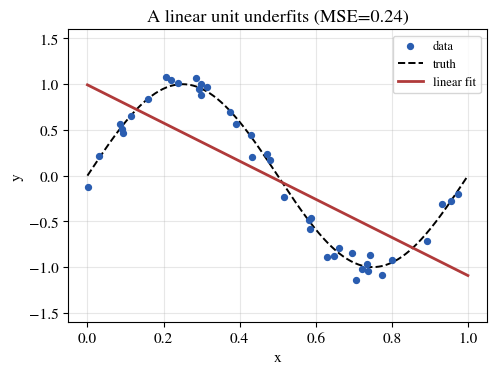

In [7]:
# ---- ddm_ex_line: a linear unit (no hidden layer) underfits a curved target --
rng_ex = np.random.default_rng(3)
g1 = lambda x: np.sin(2*np.pi*x)
xg = np.linspace(0, 1, 300)
xd = np.sort(rng_ex.uniform(0, 1, 40)); yd = g1(xd) + 0.08*rng_ex.standard_normal(40)

# linear regression == an MLP with no hidden layer: closed-form least-squares line
A1 = np.vstack([xd, np.ones_like(xd)]).T
wlin, *_ = np.linalg.lstsq(A1, yd, rcond=None)
ylin = np.vstack([xg, np.ones_like(xg)]).T @ wlin
mse_lin = np.mean((A1 @ wlin - yd)**2)

def plot_ddm_ex_line():
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    ax.scatter(xd, yd, s=18, color='C0', zorder=3, label='data')
    ax.plot(xg, g1(xg), '--', color=fg(), lw=1.4, label='truth')
    ax.plot(xg, ylin, color='C3', lw=2, label='linear fit')
    ax.set(xlabel='x', ylabel='y', ylim=(-1.6, 1.6),
           title=f'A linear unit underfits (MSE={mse_lin:.2f})')
    ax.legend(loc='upper right', fontsize=9)

save_dual(plot_ddm_ex_line, 'ddm_ex_line', FIG); plt.show()

`ddm_ex_line.png` — the best possible straight line through the noisy sine, and it is hopeless: it slices through the middle of the wave, over-shooting the crest near $x=0.25$ and under-shooting the trough near $x=0.75$, with **MSE = 0.24**. A line has no way to bend, so no amount of optimisation helps — this is the underfitting floor the hidden layer will break.

The same data, one hidden layer added: `fit_mlp_ex([1, 8, 1], ...)` — an MLP with **8 `tanh` hidden units**, the same MSE loss and Adam optimiser (4000 steps). This is the smallest step up from the line: a single learned feature layer $\boldsymbol h=\sigma(\mathbf W^{(1)}x+\boldsymbol b^{(1)})$ feeding the same linear readout, saved as `ddm_ex_nonlinear`.

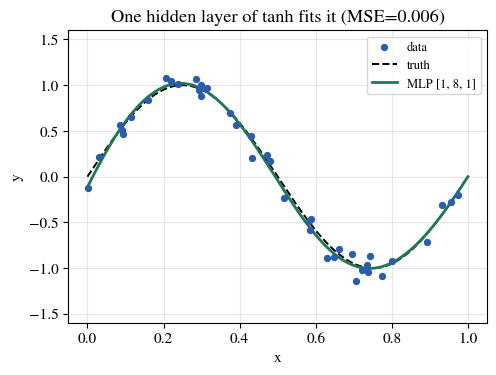

In [8]:
# ---- ddm_ex_nonlinear: one hidden layer of tanh units recovers the curve -----
def fit_mlp_ex(layers, xd, yd, iters=4000, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    net = MLP(layers)
    Xt = torch.tensor(xd).reshape(-1, 1); Yt = torch.tensor(yd).reshape(-1, 1)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(iters):
        opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
    with torch.no_grad():
        yq = net(torch.tensor(xg).reshape(-1, 1)).numpy().ravel()
    return net, yq

net_h, yh = fit_mlp_ex([1, 8, 1], xd, yd, iters=4000)
mse_h = np.mean((net_h(torch.tensor(xd).reshape(-1, 1)).detach().numpy().ravel() - yd)**2)

def plot_ddm_ex_nonlinear():
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    ax.scatter(xd, yd, s=18, color='C0', zorder=3, label='data')
    ax.plot(xg, g1(xg), '--', color=fg(), lw=1.4, label='truth')
    ax.plot(xg, yh, color='C2', lw=2, label='MLP [1, 8, 1]')
    ax.set(xlabel='x', ylabel='y', ylim=(-1.6, 1.6),
           title=f'One hidden layer of tanh fits it (MSE={mse_h:.3f})')
    ax.legend(loc='upper right', fontsize=9)

save_dual(plot_ddm_ex_nonlinear, 'ddm_ex_nonlinear', FIG); plt.show()

`ddm_ex_nonlinear.png` — the eight-unit network now overlays the dashed truth almost perfectly across the whole period, with **MSE = 0.006**, roughly **40× lower** than the line's 0.24. Nothing changed but the model: same loss, same optimiser, same 40 points. The hidden layer supplied the learned features $\boldsymbol\phi_{\boldsymbol\theta}(x)$ a straight line could not.

Now a genuinely wiggly target that no low-order fixed basis can capture:
$$ g_2(x) = \sin(2\pi x) + \tfrac12\sin(6\pi x) + \tfrac14\sin(12\pi x), $$
sampled at 160 points (noise $0.03$). As a foil, fit a **fixed cubic basis** (`np.vander(x,4)`, hand-chosen features) by least squares; then let a **deep network** `MLP([1, 64, 64, 1])` learn its own features (8000 Adam steps, `lr=3e-3`). This produces the `ddm_ex_universal` figure.

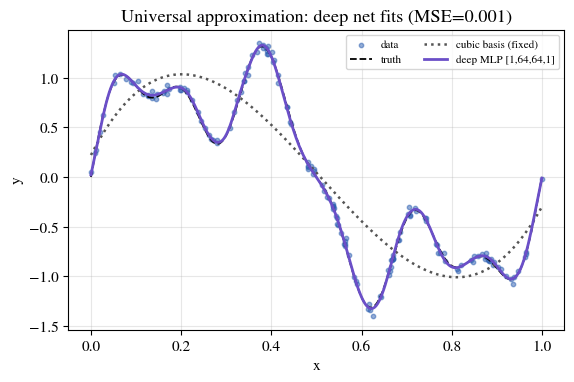

cubic-basis MSE=0.132   deep-MLP MSE=0.001


In [9]:
# ---- ddm_ex_universal: a deep tanh network is a universal approximator --------
# A genuinely wiggly target that no low-order fixed basis captures.
g2 = lambda x: np.sin(2*np.pi*x) + 0.5*np.sin(6*np.pi*x) + 0.25*np.sin(12*np.pi*x)
xd2 = np.sort(rng_ex.uniform(0, 1, 160)); yd2 = g2(xd2) + 0.03*rng_ex.standard_normal(160)

# A cubic polynomial basis (fixed, hand-chosen features) as a foil.
Ac = np.vander(xd2, 4); wc, *_ = np.linalg.lstsq(Ac, yd2, rcond=None)
ycub = np.vander(xg, 4) @ wc

# A deep tanh network learns its own features instead.
net_d, yd_fit = fit_mlp_ex([1, 64, 64, 1], xd2, yd2, iters=8000, lr=3e-3)
mse_d = np.mean((net_d(torch.tensor(xd2).reshape(-1,1)).detach().numpy().ravel() - yd2)**2)

def plot_ddm_ex_universal():
    fig, ax = plt.subplots(figsize=(6.4, 3.9))
    ax.scatter(xd2, yd2, s=10, color='C0', alpha=0.5, zorder=2, label='data')
    ax.plot(xg, g2(xg), '--', color=fg(), lw=1.3, label='truth')
    ax.plot(xg, ycub, ':', color=muted(), lw=1.8, label='cubic basis (fixed)')
    ax.plot(xg, yd_fit, color='C4', lw=2, label='deep MLP [1,64,64,1]')
    ax.set(xlabel='x', ylabel='y',
           title=f'Universal approximation: deep net fits (MSE={mse_d:.3f})')
    ax.legend(loc='upper right', fontsize=8, ncol=2)

save_dual(plot_ddm_ex_universal, 'ddm_ex_universal', FIG); plt.show()
print(f'cubic-basis MSE={np.mean((np.vander(xd2,4)@wc - yd2)**2):.3f}   deep-MLP MSE={mse_d:.3f}')

`ddm_ex_universal.png` — the cubic basis (dotted) can only draw one gentle hump and misses every fast oscillation (**MSE = 0.132**), while the deep `tanh` net tracks all three frequencies of $g_2$ almost exactly (**MSE = 0.001**, ~130× better). No features were hand-picked: the two hidden layers *learned* a basis rich enough to represent the superposition of sines. That is the **universal approximation** theorem made visible — and the same flexibility that, unchecked, let the degree-12 polynomial explode, which is why regularization and honest validation matter.

**Takeaways.** Model complexity must match the data, and the validation curve — not the training curve — is where the sweet spot shows; a split that leaves the training support turns validation into extrapolation, which no degree survives; regularization buys generalization; gradient descent needs a learning rate inside the stability limit, and mini-batch noise is a feature; and an honest training run tracks both losses, stops at the best validation epoch, and touches the test set once. The same network, loss and optimizer reappear in every later notebook.